Contoh penerapan CNN untuk klasifikasi angka dengan  Data MNIST

In [1]:
#import library
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


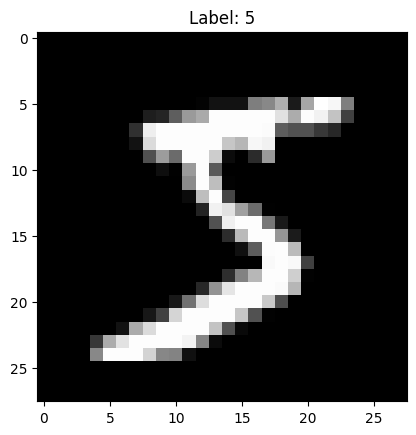

In [2]:
# Memuat data MNIST
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Mempersiapkan data input untuk CNN
# CNN membutuhkan dimensi 4D: (jumlah_gambar, tinggi, lebar, channel)
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1).astype('float32') / 255.0
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1).astype('float32') / 255.0

# Mengubah label ke format one-hot encoding
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

# Menampilkan salah satu contoh gambar
plt.imshow(x_train[0].reshape(28, 28), cmap='gray')
plt.title(f"Label: {np.argmax(y_train[0])}")
plt.show()

membangun model CNN

In [3]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

# Kompilasi model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Menampilkan ringkasan model
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Melatih model
history = model.fit(x_train, y_train, epochs=10, batch_size=128, validation_data=(x_test, y_test))

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - accuracy: 0.8128 - loss: 0.6065 - val_accuracy: 0.9812 - val_loss: 0.0594
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 79s 101ms/step - accuracy: 0.9710 - loss: 0.0998 - val_accuracy: 0.9865 - val_loss: 0.0399
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 83s 103ms/step - accuracy: 0.9787 - loss: 0.0697 - val_accuracy: 0.9874 - val_loss: 0.0331
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 52s 111ms/step - accuracy: 0.9833 - loss: 0.0543 - val_accuracy: 0.9890 - val_loss: 0.0318
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 58s 124ms/step - accuracy: 0.9854 - loss: 0.0476 - val_accuracy: 0.9917 - val_loss: 0.0249
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 51s 109ms/step - accuracy: 0.9883 - loss: 0.0399 - val_accuracy: 0.9906 - val_loss: 0.0247
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 49s 104ms/step - accuracy: 0.9890 - loss: 0.0350 - val_accuracy: 0.9917 - val_loss: 0.0235
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 83s 106ms/step - accuracy: 0.9909 - loss: 0

In [5]:
# Evaluasi model
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"Akurasi model pada data uji: {test_acc*100:.2f}%")

# Melakukan prediksi pada satu gambar
predictions = model.predict(x_test)
sample_index = 0
predicted_label = np.argmax(predictions[sample_index])
true_label = np.argmax(y_test[sample_index])

print(f"Prediksi model untuk gambar ke-{sample_index}: {predicted_label}")
print(f"Label sebenarnya: {true_label}")

313/313 - 3s - 10ms/step - accuracy: 0.9918 - loss: 0.0240
Akurasi model pada data uji: 99.18%
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Prediksi model untuk gambar ke-0: 7
Label sebenarnya: 7
